# Lid-driven cavity with a PINN (corrected)

Corrected version of the lid-driven cavity section of `PINNS.ipynb`. Changes:

- The PINN takes only $(x, y)$, so it solves the **steady** Navier–Stokes equations. The finite-difference reference is now run **to steady state** (before it stopped at $t = 0.7$, which is still transient).
- Added the **continuity equation** $u_x + v_y = 0$ to the loss. It was missing, so the velocity was never forced to be divergence-free.
- The lid boundary points no longer include the two top corners, which were being trained toward both $u = 1$ (lid) and $u = 0$ (side walls).
- More boundary points (101 per wall) and a boundary-loss weight, so the walls are not swamped by the interior residual.
- The learning-rate schedule is actually used (it was defined but the optimizer used a constant 1e-4).
- Loss histories are recorded correctly (the old loop appended a leftover variable from the Klein–Gordon section).
- $u$, $v$ and $p$ are all compared with the reference, with relative L2 errors.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from time import time
from scipy.optimize import minimize

tf.random.set_seed(0)
np.random.seed(0)
print(tf.__version__)

TRAIN = False     # True: retrain (about 1 h on a CPU). False: load the trained weights in weights/
N_CAV = 30000     # Adam epochs (use a small value for a quick check)
N_LBFGS = 10000   # maximum L-BFGS iterations after Adam

os.makedirs("weights", exist_ok=True)
W_ADAM = "weights/corrected_pinn_cavity_adam.weights.h5"     # after Adam
W_FINAL = "weights/corrected_pinn_cavity.weights.h5"         # after Adam + L-BFGS
W_ORIGINAL = "weights/original_pinn_cavity.weights.h5"       # original notebook's PINN

2.21.0


In [2]:
def mlp(n_out, num_layers=8, size_layer=60):
    model = keras.Sequential([keras.Input((2,))])
    for _ in range(num_layers):
        model.add(keras.layers.Dense(size_layer, activation="tanh",
                                     kernel_initializer="glorot_normal"))
    model.add(keras.layers.Dense(n_out))
    return model


def rel_l2(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)


def train(loss_fn, model, n_steps, lr, print_every=5000):
    # loss_fn() returns (total_loss, dict_of_components)
    optimizer = keras.optimizers.Adam(learning_rate=lr)

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            loss, parts = loss_fn()
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        return loss, parts

    hist = {}
    t0 = time()
    for i in range(n_steps + 1):
        loss, parts = step()
        for k, v in {"total": loss, **parts}.items():
            hist.setdefault(k, []).append(float(v))
        if i % print_every == 0:
            print(f"step {i:6d}  " + "  ".join(f"{k}={hist[k][-1]:.3e}" for k in hist))
    print(f"training time: {time() - t0:.0f} s")
    return hist


def plot_history(hist, title):
    plt.figure(figsize=(6, 4))
    for k, v in hist.items():
        plt.semilogy(v, label=k)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(title); plt.legend()
    plt.show()

# Lid-driven cavity (steady)

The network maps $(x,y)\mapsto(u,v,p)$, so it solves the **steady** equations on $[0,2]^2$:

$$u u_x + v u_y + \tfrac{1}{\rho}p_x - \nu(u_{xx}+u_{yy}) = 0,\qquad
u v_x + v v_y + \tfrac{1}{\rho}p_y - \nu(v_{xx}+v_{yy}) = 0,\qquad
u_x + v_y = 0.$$

Boundary conditions (same as the finite-difference reference): $u=1, v=0, p=0$ on the lid $y=2$; $u=v=0$ on the other walls; $p_y=0$ at $y=0$; $p_x=0$ at $x=0,2$. With $\rho=1$, $\nu=0.1$, $Re = UL/\nu = 20$.

In [3]:
rho, nu = 1.0, 0.1
n_wall = 101
s = tf.reshape(tf.linspace(0., 2., n_wall), (-1, 1))
s_open = s[1:-1]                                  # lid without its two corner points

Z_bottom = tf.concat([s, tf.zeros_like(s)], 1)
Z_left = tf.concat([tf.zeros_like(s), s], 1)      # includes both left corners (u = v = 0)
Z_right = tf.concat([2. * tf.ones_like(s), s], 1)  # includes both right corners (u = v = 0)
Z_lid = tf.concat([s_open, 2. * tf.ones_like(s_open)], 1)

Z_int = tf.random.uniform((2601, 2), 0., 2.)     # interior collocation points


def cavity_derivatives(model, Z):
    x, y = Z[:, 0:1], Z[:, 1:2]
    with tf.GradientTape(persistent=True) as t2:
        t2.watch([x, y])
        with tf.GradientTape(persistent=True) as t1:
            t1.watch([x, y])
            out = model(tf.concat([x, y], 1))
            u, v, p = out[:, 0:1], out[:, 1:2], out[:, 2:3]
        u_x, u_y = t1.gradient(u, x), t1.gradient(u, y)
        v_x, v_y = t1.gradient(v, x), t1.gradient(v, y)
        p_x, p_y = t1.gradient(p, x), t1.gradient(p, y)
    u_xx, u_yy = t2.gradient(u_x, x), t2.gradient(u_y, y)
    v_xx, v_yy = t2.gradient(v_x, x), t2.gradient(v_y, y)
    return dict(u=u, v=v, p=p, u_x=u_x, u_y=u_y, v_x=v_x, v_y=v_y, p_x=p_x, p_y=p_y,
                u_xx=u_xx, u_yy=u_yy, v_xx=v_xx, v_yy=v_yy)


def pressure_grad(model, Z, wrt):
    x, y = Z[:, 0:1], Z[:, 1:2]
    with tf.GradientTape() as tape:
        tape.watch(x if wrt == "x" else y)
        p = model(tf.concat([x, y], 1))[:, 2:3]
    return tape.gradient(p, x if wrt == "x" else y)


W_BC = 10.0   # boundary-loss weight


def cavity_loss_fn(model):
    def loss_fn():
        d = cavity_derivatives(model, Z_int)
        r_x = d["u"]*d["u_x"] + d["v"]*d["u_y"] + d["p_x"]/rho - nu*(d["u_xx"] + d["u_yy"])
        r_y = d["u"]*d["v_x"] + d["v"]*d["v_y"] + d["p_y"]/rho - nu*(d["v_xx"] + d["v_yy"])
        r_c = d["u_x"] + d["v_y"]
        l_res = tf.reduce_mean(r_x**2) + tf.reduce_mean(r_y**2) + tf.reduce_mean(r_c**2)

        no_slip = tf.concat([Z_bottom, Z_left, Z_right], 0)
        out_w = model(no_slip)
        out_lid = model(Z_lid)
        l_vel = (tf.reduce_mean(out_w[:, 0]**2) + tf.reduce_mean(out_w[:, 1]**2)
                 + tf.reduce_mean((out_lid[:, 0] - 1.)**2) + tf.reduce_mean(out_lid[:, 1]**2))
        l_p = (tf.reduce_mean(out_lid[:, 2]**2)
               + tf.reduce_mean(pressure_grad(model, Z_bottom, "y")**2)
               + tf.reduce_mean(pressure_grad(model, Z_left, "x")**2)
               + tf.reduce_mean(pressure_grad(model, Z_right, "x")**2))
        total = l_res + W_BC * (l_vel + l_p)
        return total, {"res": l_res, "bc_vel": l_vel, "bc_p": l_p}
    return loss_fn


lr = keras.optimizers.schedules.PiecewiseConstantDecay(
    [int(0.3 * N_CAV), int(0.7 * N_CAV)], [1e-3, 3e-4, 1e-4])
model_cav = mlp(3)
if TRAIN:
    hist = train(cavity_loss_fn(model_cav), model_cav, N_CAV, lr=lr)
    model_cav.save_weights(W_ADAM)   # keep the Adam result for comparison

## Second stage: L-BFGS

Adam gets the network close to a minimum but stalls (the loss oscillates). A quasi-Newton optimizer (L-BFGS) then refines it, which is standard practice for PINNs. The network weights are flattened into one vector and passed to `scipy.optimize.minimize`, with the loss and its gradient computed by TensorFlow.

In [4]:
def lbfgs(loss_fn, model, max_iter, hist, print_every=500):
    variables = model.trainable_variables
    shapes = [v.shape for v in variables]
    sizes = [int(np.prod(s)) for s in shapes]

    def assign(w):
        for v, chunk, shape in zip(variables, tf.split(w, sizes), shapes):
            v.assign(tf.reshape(chunk, shape))

    @tf.function
    def value_and_grad(w):
        assign(w)
        with tf.GradientTape() as tape:
            loss, parts = loss_fn()
        grads = tape.gradient(loss, variables)
        return loss, tf.concat([tf.reshape(g, [-1]) for g in grads], 0), parts

    state = {"it": 0, "parts": None}

    def fun(w):
        loss, g, parts = value_and_grad(tf.constant(w, tf.float32))
        state["parts"] = parts
        return float(loss), g.numpy().astype(np.float64)

    def callback(w):
        state["it"] += 1
        loss, parts = state["last"]
        for k, v in {"total": loss, **parts}.items():
            hist.setdefault(k, []).append(float(v))
        if state["it"] % print_every == 0:
            print(f"L-BFGS iter {state['it']:6d}  " + "  ".join(f"{k}={hist[k][-1]:.3e}" for k in hist))

    def fun_logged(w):
        f, g = fun(w)
        state["last"] = (f, state["parts"])
        return f, g

    w0 = tf.concat([tf.reshape(v, [-1]) for v in variables], 0).numpy().astype(np.float64)
    t0 = time()
    res = minimize(fun_logged, w0, jac=True, method="L-BFGS-B", callback=callback,
                   options={"maxiter": max_iter, "maxfun": 2 * max_iter, "maxcor": 50,
                            "ftol": 1e-14, "gtol": 1e-10})
    assign(tf.constant(res.x, tf.float32))
    print(f"L-BFGS finished: {res.nit} iterations, final loss {res.fun:.3e} ({res.message}), "
          f"{time() - t0:.0f} s")
    return hist


if TRAIN:
    n_adam = len(hist["total"])
    hist = lbfgs(cavity_loss_fn(model_cav), model_cav, N_LBFGS, hist)
    model_cav.save_weights(W_FINAL)
else:
    model_cav.load_weights(W_FINAL)

if TRAIN:
    plt.figure(figsize=(6, 4))
    for k, v in hist.items():
        plt.semilogy(v, label=k)
    plt.axvline(n_adam, color="k", ls="--", lw=1)
    plt.text(n_adam, plt.ylim()[1], " L-BFGS", va="top")
    plt.xlabel("iteration (Adam, then L-BFGS)"); plt.ylabel("loss"); plt.legend()
    plt.title("Lid-driven cavity training")
    plt.show()

Training loss from the run that produced the saved weights (Adam, then L-BFGS after the dashed line):

![training loss](figures/training_loss.png)

## Finite-difference reference, run to steady state
Same projection scheme as before (Barba, *12 steps to Navier–Stokes*), but time-stepped until the velocity stops changing instead of stopping at $t=0.7$.

In [5]:
nx = ny = 41
dx = dy = 2 / (nx - 1)
dt, nit = 0.001, 50


def build_up_b(u, v):
    b = np.zeros_like(u)
    b[1:-1, 1:-1] = rho * (1 / dt * ((u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
                                     + (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy))
                           - ((u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx))**2
                           - 2 * ((u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
                                  * (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx))
                           - ((v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy))**2)
    return b


def pressure_poisson(p, b):
    for _ in range(nit):
        pn = p.copy()
        p[1:-1, 1:-1] = (((pn[1:-1, 2:] + pn[1:-1, :-2]) * dy**2
                          + (pn[2:, 1:-1] + pn[:-2, 1:-1]) * dx**2) / (2 * (dx**2 + dy**2))
                         - dx**2 * dy**2 / (2 * (dx**2 + dy**2)) * b[1:-1, 1:-1])
        p[:, -1] = p[:, -2]; p[0, :] = p[1, :]; p[:, 0] = p[:, 1]; p[-1, :] = 0
    return p


def cavity_steady(tol=1e-7, max_steps=20000):
    u = np.zeros((ny, nx)); v = np.zeros((ny, nx)); p = np.zeros((ny, nx))
    for n in range(max_steps):
        un, vn = u.copy(), v.copy()
        p = pressure_poisson(p, build_up_b(u, v))
        u[1:-1, 1:-1] = (un[1:-1, 1:-1]
                         - un[1:-1, 1:-1] * dt / dx * (un[1:-1, 1:-1] - un[1:-1, :-2])
                         - vn[1:-1, 1:-1] * dt / dy * (un[1:-1, 1:-1] - un[:-2, 1:-1])
                         - dt / (2 * rho * dx) * (p[1:-1, 2:] - p[1:-1, :-2])
                         + nu * (dt / dx**2 * (un[1:-1, 2:] - 2 * un[1:-1, 1:-1] + un[1:-1, :-2])
                                 + dt / dy**2 * (un[2:, 1:-1] - 2 * un[1:-1, 1:-1] + un[:-2, 1:-1])))
        v[1:-1, 1:-1] = (vn[1:-1, 1:-1]
                         - un[1:-1, 1:-1] * dt / dx * (vn[1:-1, 1:-1] - vn[1:-1, :-2])
                         - vn[1:-1, 1:-1] * dt / dy * (vn[1:-1, 1:-1] - vn[:-2, 1:-1])
                         - dt / (2 * rho * dy) * (p[2:, 1:-1] - p[:-2, 1:-1])
                         + nu * (dt / dx**2 * (vn[1:-1, 2:] - 2 * vn[1:-1, 1:-1] + vn[1:-1, :-2])
                                 + dt / dy**2 * (vn[2:, 1:-1] - 2 * vn[1:-1, 1:-1] + vn[:-2, 1:-1])))
        u[0, :] = 0; u[:, 0] = 0; u[:, -1] = 0; u[-1, :] = 1
        v[0, :] = 0; v[-1, :] = 0; v[:, 0] = 0; v[:, -1] = 0
        change = max(np.abs(u - un).max(), np.abs(v - vn).max())
        if n > 100 and change < tol:
            break
    print(f"steady state after {n + 1} steps (t = {(n + 1) * dt:.2f}), last change {change:.1e}")
    return u, v, p


u_fd, v_fd, p_fd = cavity_steady()

steady state after 5941 steps (t = 5.94), last change 1.0e-07


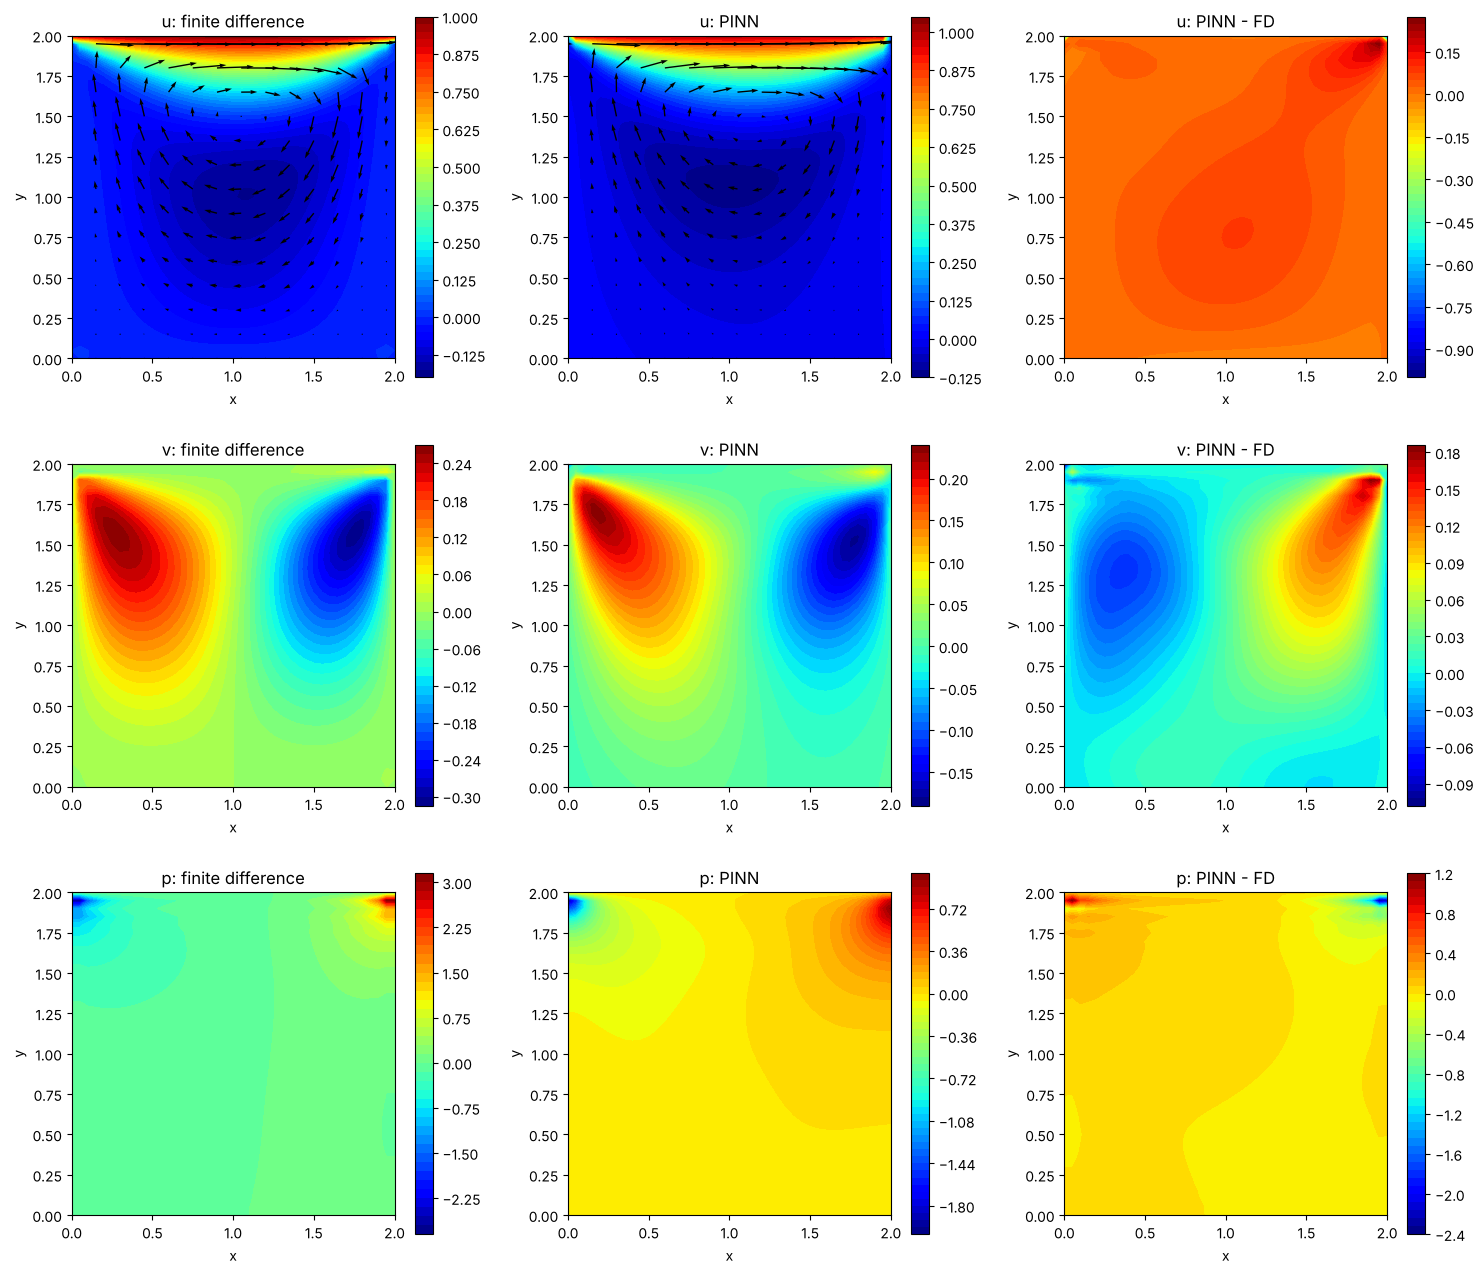

                           Adam only                 Adam + L-BFGS
field   rel. L2 (all) rel. L2 (int.)  rel. L2 (all) rel. L2 (int.)
u           3.190e-01      3.999e-01      2.043e-01      2.149e-01
v           7.312e-01      7.278e-01      4.054e-01      4.036e-01
p           9.626e-01      9.733e-01      4.882e-01      4.940e-01


In [6]:
x = np.linspace(0, 2, nx, dtype=np.float32)
y = np.linspace(0, 2, ny, dtype=np.float32)
X, Y = np.meshgrid(x, y)
out = model_cav(np.stack([X.ravel(), Y.ravel()], 1)).numpy()
u_pinn, v_pinn, p_pinn = (out[:, k].reshape(X.shape) for k in range(3))

fig, ax = plt.subplots(3, 3, figsize=(15, 13))
for r, (fd, pn, name) in enumerate([(u_fd, u_pinn, "u"), (v_fd, v_pinn, "v"), (p_fd, p_pinn, "p")]):
    for c, (f, lab) in enumerate([(fd, "finite difference"), (pn, "PINN"), (pn - fd, "PINN - FD")]):
        h = ax[r, c].contourf(X, Y, f, levels=50, cmap="jet")
        if c < 2 and name == "u":
            uu, vv = (u_fd, v_fd) if c == 0 else (u_pinn, v_pinn)
            ax[r, c].quiver(X[::3, ::3], Y[::3, ::3], uu[::3, ::3], vv[::3, ::3])
        ax[r, c].set(title=f"{name}: {lab}", xlabel="x", ylabel="y", aspect="equal")
        fig.colorbar(h, ax=ax[r, c])
plt.tight_layout(); plt.show()

model_adam = mlp(3)
model_adam.load_weights(W_ADAM)
out_adam = model_adam(np.stack([X.ravel(), Y.ravel()], 1)).numpy()
interior = np.s_[1:-1, 1:-1]   # excludes the wall nodes, where the two methods treat the lid corners differently

print(f"{'':6s}{'Adam only':>30s}{'Adam + L-BFGS':>30s}")
print(f"{'field':6s}{'rel. L2 (all)':>15s}{'rel. L2 (int.)':>15s}{'rel. L2 (all)':>15s}{'rel. L2 (int.)':>15s}")
for k, (name, fd, pn) in enumerate([("u", u_fd, u_pinn), ("v", v_fd, v_pinn), ("p", p_fd, p_pinn)]):
    pa = out_adam[:, k].reshape(X.shape)
    print(f"{name:6s}{rel_l2(pa, fd):15.3e}{rel_l2(pa[interior], fd[interior]):15.3e}"
          f"{rel_l2(pn, fd):15.3e}{rel_l2(pn[interior], fd[interior]):15.3e}")

## Centerline velocities and flow field: original vs corrected

Comparison of three solutions:
- **Finite difference, steady**: the reference, run to steady state.
- **Original PINN**: the network from the original `PINNS.ipynb` (no continuity equation, lid corners in conflict, 10 points per wall, constant learning rate), retrained with the original code and loaded from `weights/original_pinn_cavity.weights.h5`.
- **Corrected PINN**: this notebook, after Adam only and after Adam + L-BFGS (the centerline plots show both; the streamline plot shows the final Adam + L-BFGS network).

The original notebook's reference (finite difference stopped at $t = 0.7$) is also shown, to show how far it was from steady state.

Centerlines: $u(y)$ along the vertical line $x = 1$, and $v(x)$ along the horizontal line $y = 1$.

steady state after 700 steps (t = 0.70), last change 1.8e-04


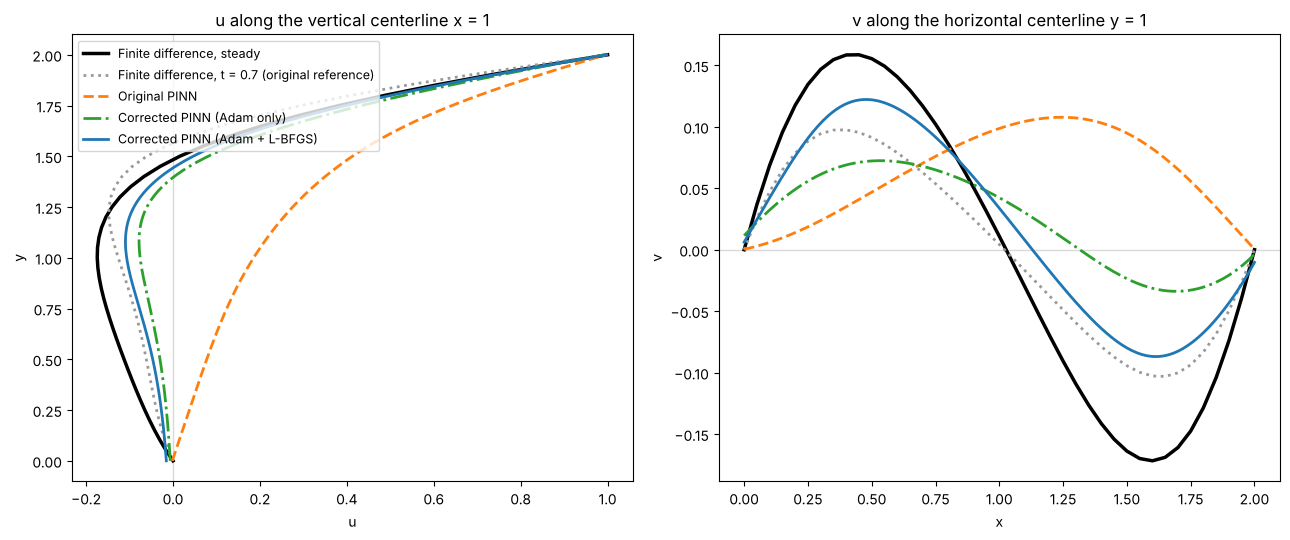

Original PINN                    centerline rel. L2 error:  u = 0.949   v = 1.285
Corrected PINN (Adam only)       centerline rel. L2 error:  u = 0.242   v = 0.728
Corrected PINN (Adam + L-BFGS)   centerline rel. L2 error:  u = 0.166   v = 0.419
FD at t = 0.7                    centerline rel. L2 error:  u = 0.180   v = 0.406


In [7]:
# finite-difference solution at t = 0.7: the reference used in the original notebook
u_fd07, v_fd07, p_fd07 = cavity_steady(tol=0.0, max_steps=700)

model_orig = mlp(3)
model_orig.load_weights(W_ORIGINAL)

line = np.linspace(0, 2, 201, dtype=np.float32)
def on_points(model, xs, ys):
    out = model(np.stack([xs, ys], 1)).numpy()
    return out[:, 0], out[:, 1]

i_mid = nx // 2                                   # x = 1 (and y = 1) on the 41-point grid
models = [("Original PINN", model_orig, "tab:orange", "--"),
          ("Corrected PINN (Adam + L-BFGS)", model_cav, "tab:blue", "-")]
centerline_models = [models[0],
                     ("Corrected PINN (Adam only)", model_adam, "tab:green", "-."),
                     models[1]]

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
# u along x = 1
ax[0].plot(u_fd[:, i_mid], y, "k-", lw=2.5, label="Finite difference, steady")
ax[0].plot(u_fd07[:, i_mid], y, color="0.6", ls=":", lw=2, label="Finite difference, t = 0.7 (original reference)")
for name, m, col, ls in centerline_models:
    u_l, _ = on_points(m, np.ones_like(line), line)
    ax[0].plot(u_l, line, color=col, ls=ls, lw=2, label=name)
ax[0].set(xlabel="u", ylabel="y", title="u along the vertical centerline x = 1")
ax[0].axvline(0, color="0.85", lw=1, zorder=0)
# v along y = 1
ax[1].plot(x, v_fd[i_mid, :], "k-", lw=2.5, label="Finite difference, steady")
ax[1].plot(x, v_fd07[i_mid, :], color="0.6", ls=":", lw=2, label="Finite difference, t = 0.7 (original reference)")
for name, m, col, ls in centerline_models:
    _, v_l = on_points(m, line, np.ones_like(line))
    ax[1].plot(line, v_l, color=col, ls=ls, lw=2, label=name)
ax[1].set(xlabel="x", ylabel="v", title="v along the horizontal centerline y = 1")
ax[1].axhline(0, color="0.85", lw=1, zorder=0)
ax[0].legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

# centerline errors against the steady reference
for name, m, _, _ in centerline_models:
    u_c, _ = on_points(m, np.ones(ny, np.float32), y)
    _, v_c = on_points(m, x, np.ones(nx, np.float32))
    print(f"{name:32s} centerline rel. L2 error:  u = {rel_l2(u_c, u_fd[:, i_mid]):.3f}   "
          f"v = {rel_l2(v_c, v_fd[i_mid, :]):.3f}")
print(f"{'FD at t = 0.7':32s} centerline rel. L2 error:  u = {rel_l2(u_fd07[:, i_mid], u_fd[:, i_mid]):.3f}   "
      f"v = {rel_l2(v_fd07[i_mid, :], v_fd[i_mid, :]):.3f}")

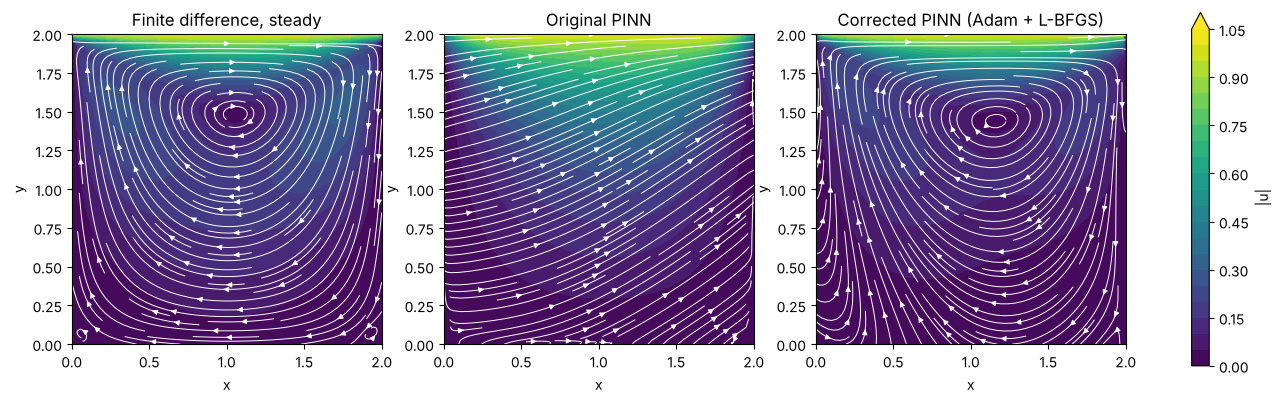

Original PINN, interior rel. L2 error vs steady FD:  u = 1.194  v = 1.322  p = 1.267


In [8]:
# Velocity magnitude and streamlines
xf = np.linspace(0, 2, 101, dtype=np.float32)
Xf, Yf = np.meshgrid(xf, xf)
fields = [("Finite difference, steady", u_fd, v_fd, X, Y)]
for name, m, _, _ in models:
    out = m(np.stack([Xf.ravel(), Yf.ravel()], 1)).numpy()
    fields.append((name, out[:, 0].reshape(Xf.shape), out[:, 1].reshape(Xf.shape), Xf, Yf))

fig, ax = plt.subplots(1, 3, figsize=(17, 5.4))
for a, (name, uu, vv, XX, YY) in zip(ax, fields):
    speed = np.sqrt(uu**2 + vv**2)
    h = a.contourf(XX, YY, speed, levels=np.linspace(0, 1.05, 22), cmap="viridis", extend="max")
    a.streamplot(XX[0], YY[:, 0], uu, vv, color="w", density=1.4, linewidth=0.7, arrowsize=0.8)
    a.set(title=name, xlabel="x", ylabel="y", aspect="equal", xlim=(0, 2), ylim=(0, 2))
fig.colorbar(h, ax=ax, label="|u|", shrink=0.85)
plt.show()

# whole-field errors of the original PINN for reference
out_o = model_orig(np.stack([X.ravel(), Y.ravel()], 1)).numpy()
print("Original PINN, interior rel. L2 error vs steady FD:  "
      + "  ".join(f"{n} = {rel_l2(out_o[:, k].reshape(X.shape)[interior], f[interior]):.3f}"
                  for k, (n, f) in enumerate([("u", u_fd), ("v", v_fd), ("p", p_fd)])))